In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
heart_disease = fetch_ucirepo(id=45) 
  
# data (as pandas dataframes) 
X = heart_disease.data.features 
y = heart_disease.data.targets 

In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1502)
data_train = X_train.copy()
data_train['target'] = y_train['num']
X_train.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
299,68,1,4,144,193,1,0,141,0,3.4,2,2.0,7.0
270,61,1,4,140,207,0,2,138,1,1.9,1,1.0,7.0
214,52,1,4,112,230,0,0,160,0,0.0,1,1.0,3.0
33,59,1,4,135,234,0,0,161,0,0.5,2,0.0,7.0
234,54,0,3,160,201,0,0,163,0,0.0,1,1.0,3.0


# EDA

### Y

<Axes: >

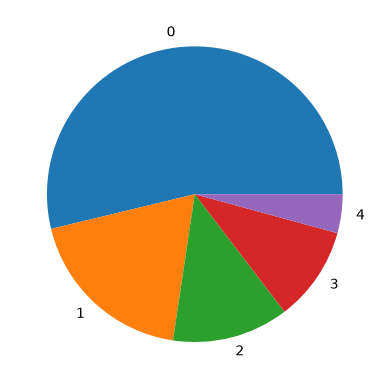

In [4]:
y_train['num'].value_counts().plot(kind='pie')

### X

In [5]:
X_train.isna().sum(axis=0)

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        1
dtype: int64

Univariante analysis

In [25]:
num_col = ['trestbps', 'chol', 'thalach', 'oldpeak', 'age']
cat_col = ['_', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

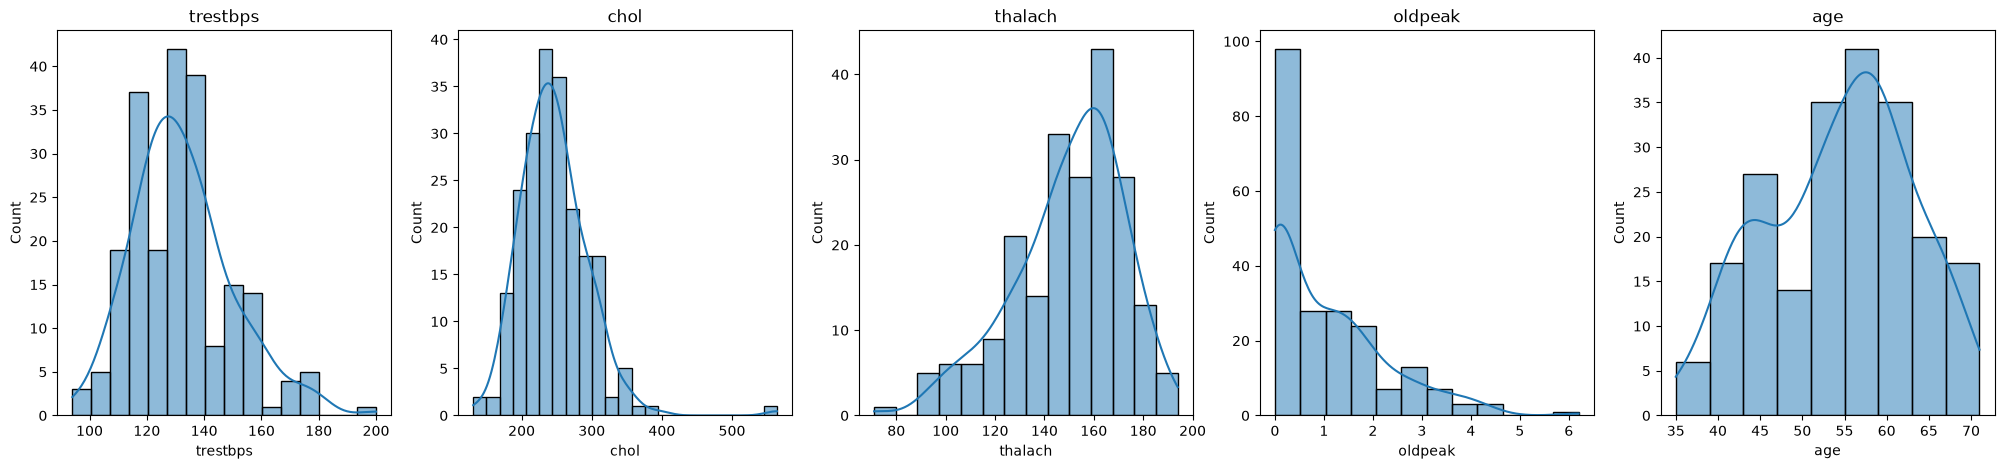

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

n_graphs = len(num_col)
fig, ax = plt.subplots(1, n_graphs, figsize=(25,5))
i=0

for col in num_col:
    histplot = sns.histplot(data=X_train, x=col, kde=True, ax=ax[i])
    histplot.set_title(col)
    i+=1

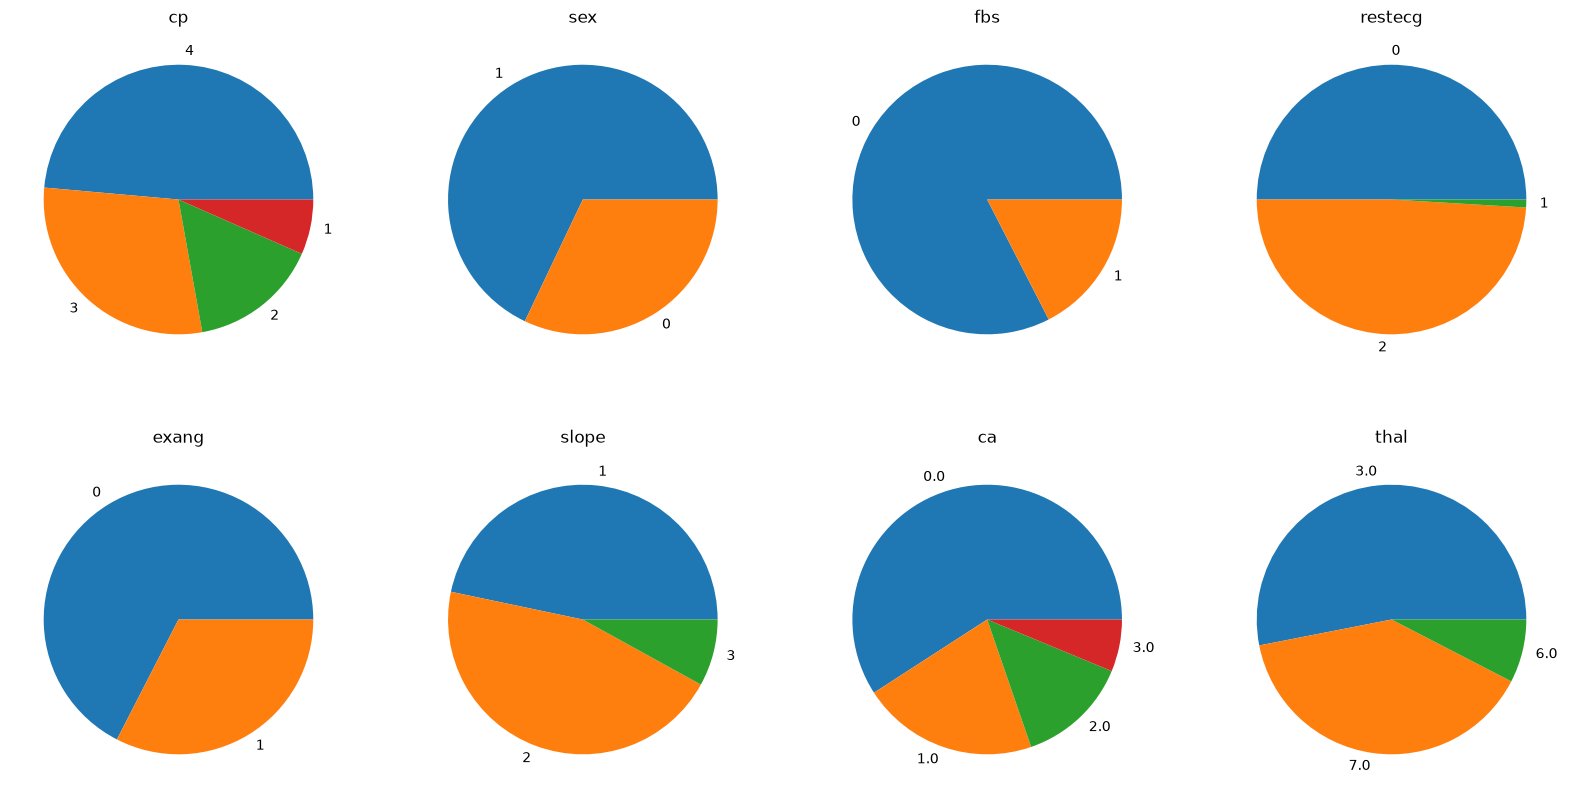

In [33]:
fig, ax = plt.subplots(2,4,figsize=(20,10))
i=0
j=0

for col in cat_col:
    X_train[col].value_counts().plot(kind='pie',ax=ax[i,j], title=col)
    j+=1
    if j%4==0:
        j=0
        i+=1

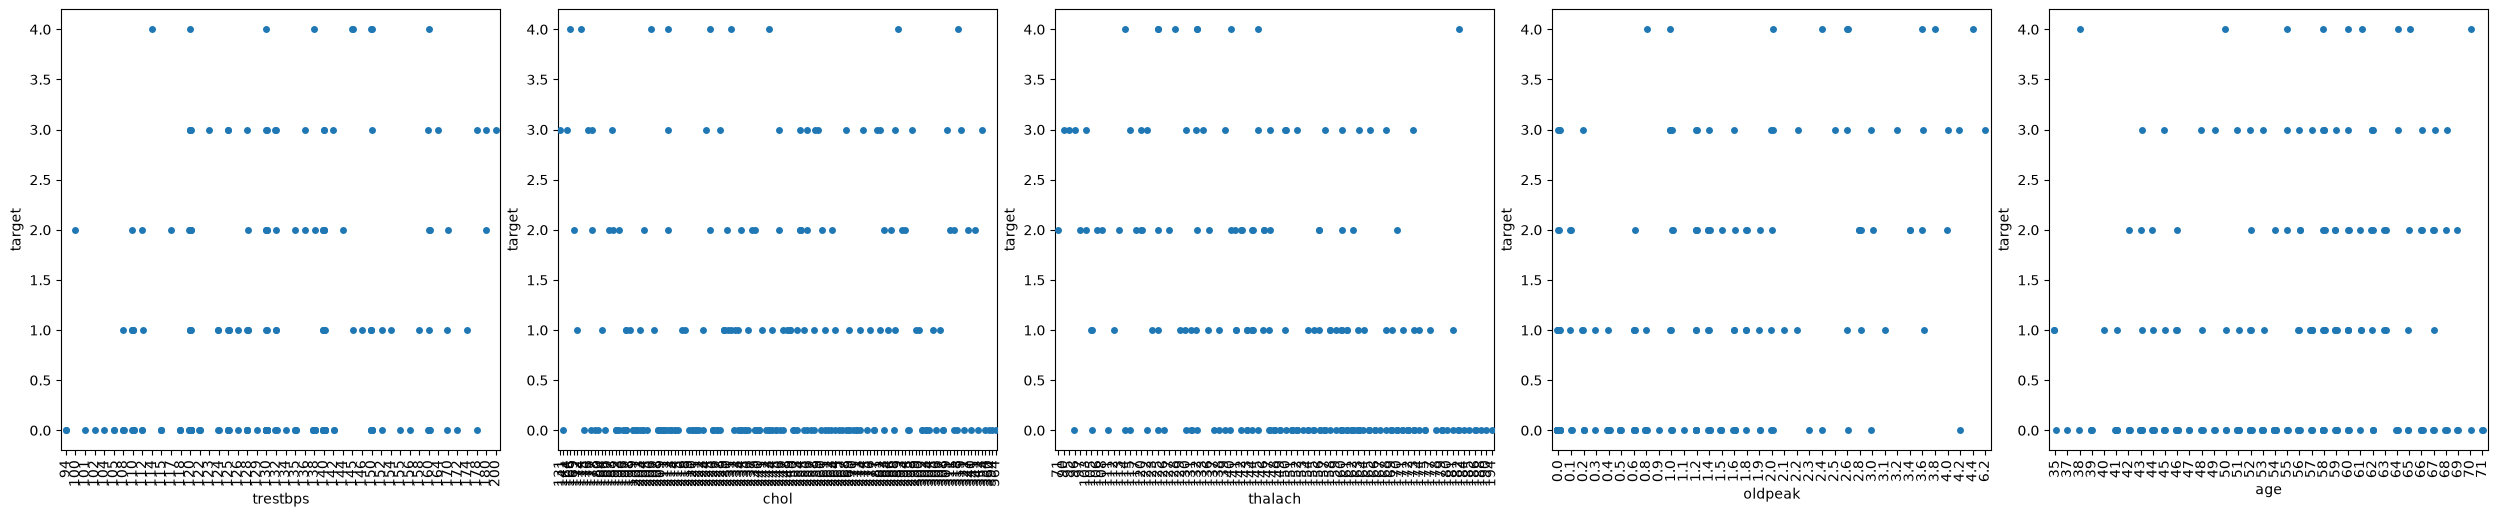

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

n_graphs = len(num_col)
fig, ax = plt.subplots(1, n_graphs, figsize=(25,5))
i=0

plt.tight_layout()
for col in num_col:
    plot = sns.stripplot(data=data_train, x=col, y='target', ax=ax[i])
    plot.tick_params(axis="x", rotation=90)
    i+=1